# Sample Covariance When Variables Are Many

The sample covariance is a scaled cross-product of centered observations, so its rank cannot exceed the smaller available dimension:

$$
S=\frac{1}{T-1}X_c^{\mathsf T}X_c,
\qquad
\operatorname{rank}(S)\leq\min\{N,T-1\}.
$$

Here, $X_c$ is the $T\times N$ centered return matrix; $T$ is the number of dates; $N$ is the number of portfolios. $S$ is the $N\times N$ sample covariance matrix; $\mathsf T$ denotes transpose; $\operatorname{rank}$ counts independent directions.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import io
import zipfile
DATA_URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'ken_french'
DATA_PATH = ensure_dataset(ROOT, 'french_49_industries')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode('latin1').splitlines()
header_row = next((index for index, line in enumerate(public_lines) if line.startswith(',Agric')))
end_row = next((index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip()))
raw = pd.read_csv(io.StringIO('\n'.join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: 'Date'})
raw['Date'] = pd.to_datetime(raw['Date'].astype(str), format='%Y%m%d')
raw = raw.set_index('Date').replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc['2019-01-01':'2025-12-31'].dropna().copy()
from RiskLabAI.data.denoise import corr_to_cov, cov_to_corr, denoise_cov, denoised_corr, denoised_corr2, find_max_eval, fit_kde, marcenko_pastur_pdf, nercome_denoised_covariance, optimal_portfolio, pca
from RiskLabAI.data.denoise.denoising import optimal_portfolio_denoised
FIGURES = ROOT / 'outputs' / 'figures' / '10_covariance_denoising'
TABLES = ROOT / 'outputs' / 'tables' / '10_covariance_denoising'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Public Industry Returns

,Field,Value
0,Archive,49_Industry_Portfolios_daily_CSV.zip
1,Provider,Kenneth R. French Data Library
2,Provider database vintage,202608 CRSP database
3,Return type,Daily value-weighted return
4,Analysis start,2019-01-02
5,Analysis end,2025-12-31
6,Analysis dates,"1,760"
7,Industry portfolios,49


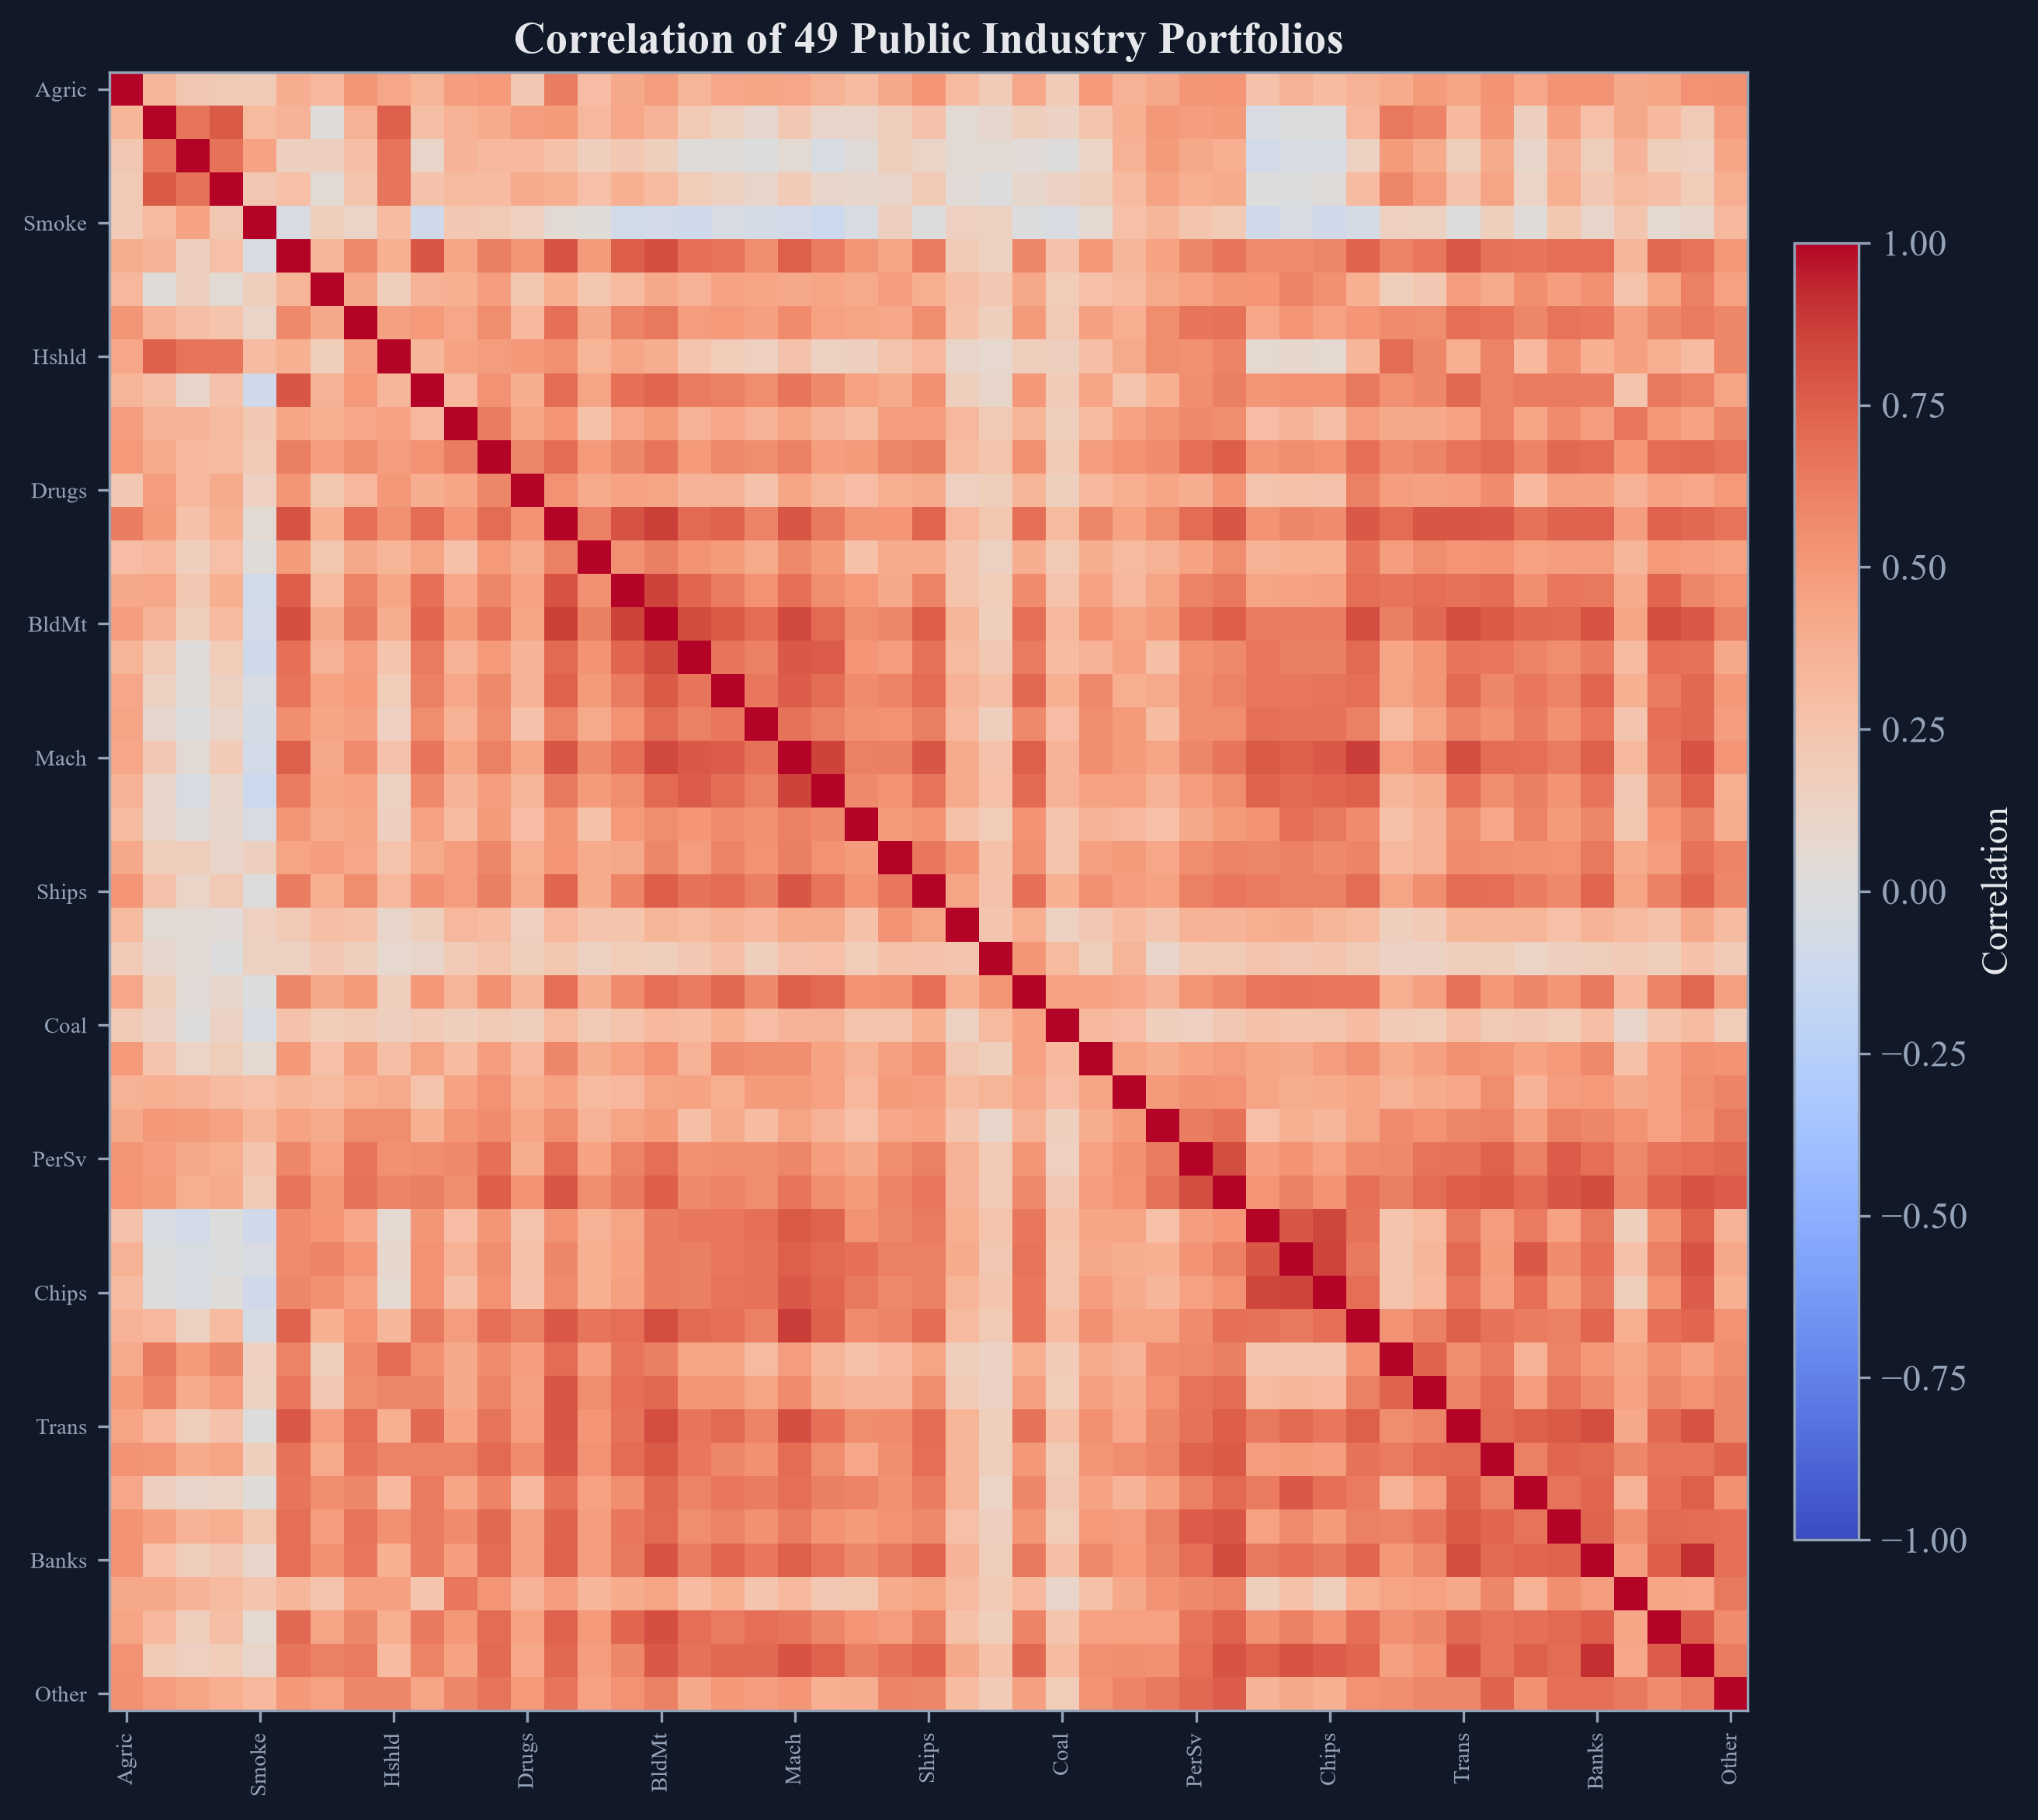

In [2]:
data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Provider database vintage', 'Return type', 'Analysis start', 'Analysis end', 'Analysis dates', 'Industry portfolios'], 'Value': ['49_Industry_Portfolios_daily_CSV.zip', 'Kenneth R. French Data Library', '202608 CRSP database', 'Daily value-weighted return', str(industry_returns.index.min().date()), str(industry_returns.index.max().date()), f'{len(industry_returns):,}', str(industry_returns.shape[1])]})
save_table(data_provenance, 'data_provenance', 'Public data used in Chapter 9.', 'tab:chapter9-data-provenance', fit=True)
display(data_provenance)
correlation_window = industry_returns.tail(252)
correlation = correlation_window.corr()
figure, axis = plt.subplots(figsize=(9.2, 7.7), constrained_layout=True)
image = axis.imshow(correlation.to_numpy(), cmap='coolwarm', vmin=-1.0, vmax=1.0)
tick_positions = np.arange(0, len(correlation.columns), 4)
axis.set_xticks(tick_positions, correlation.columns[tick_positions], rotation=90, fontsize=7)
axis.set_yticks(tick_positions, correlation.columns[tick_positions], fontsize=7)
axis.set_title('Correlation of 49 Public Industry Portfolios')
figure.colorbar(image, ax=axis, fraction=0.035, pad=0.025, label='Correlation')
figure.savefig(FIGURES / 'industry_correlation.png', bbox_inches='tight', dpi=300)
figure.savefig(FIGURES / 'industry_correlation.pdf', bbox_inches='tight')
display(Image(filename=str(FIGURES / 'industry_correlation.png')))
plt.close(figure)


## Diagnosing covariance instability

The eigenvalues divide total correlation across directions; the condition number measures spread between the largest and smallest directions:

$$
C=Q\Lambda Q^{\mathsf T},
\qquad
\kappa_2(C)=\frac{\lambda_{\max}}{\lambda_{\min}},
\qquad
r_{\mathrm{eff}}=\exp\!\left(-\sum_{i=1}^{N}\pi_i\log\pi_i\right),
\quad
\pi_i=\frac{\lambda_i}{\sum_{j=1}^{N}\lambda_j}.
$$

Here, Effective rank is the number of equally weighted directions that would have the same eigenvalue entropy. $C$ is a correlation matrix; $Q$ contains orthonormal eigenvectors; $\Lambda$ is diagonal with eigenvalues $\lambda_i.$ $\lambda_{\max},\lambda_{\min}$ are the largest and smallest positive eigenvalues; $\kappa_2$ is the spectral condition number. $\pi_i$ is eigenvalue $i$ divided by their sum; $r_{\mathrm{eff}}$ is effective rank; $N$ is the number of portfolios.

,Observations,Portfolios,Observation to portfolio ratio,Rank,Near-zero eigenvalues,Smallest eigenvalue,Largest eigenvalue,Condition number,Effective rank
0,30,49,0.612245,29,20,0,21.260792,inf,8.722408
1,49,49,1,48,1,0,17.914458,inf,12.007302
2,75,49,1.530612,49,0,0.019764,17.335745,877.126167,14.098420
3,125,49,2.551020,49,0,0.048483,16.814293,346.804990,16.375923
4,252,49,5.142857,49,0,0.043430,24.404294,561.918400,10.261849


,Ordered direction,Eigenvalue,Share of total correlation,Cumulative share
0,1,16.814293,0.343149,0.343149
1,2,6.251277,0.127577,0.470726
2,3,2.481292,0.050639,0.521365
3,4,1.760603,0.035931,0.557295
4,5,1.544645,0.031523,0.588819
5,6,1.495682,0.030524,0.619343
6,7,1.382980,0.028224,0.647567
7,8,1.239602,0.025298,0.672865
8,9,1.115271,0.022761,0.695625
9,10,1.044942,0.021325,0.716951


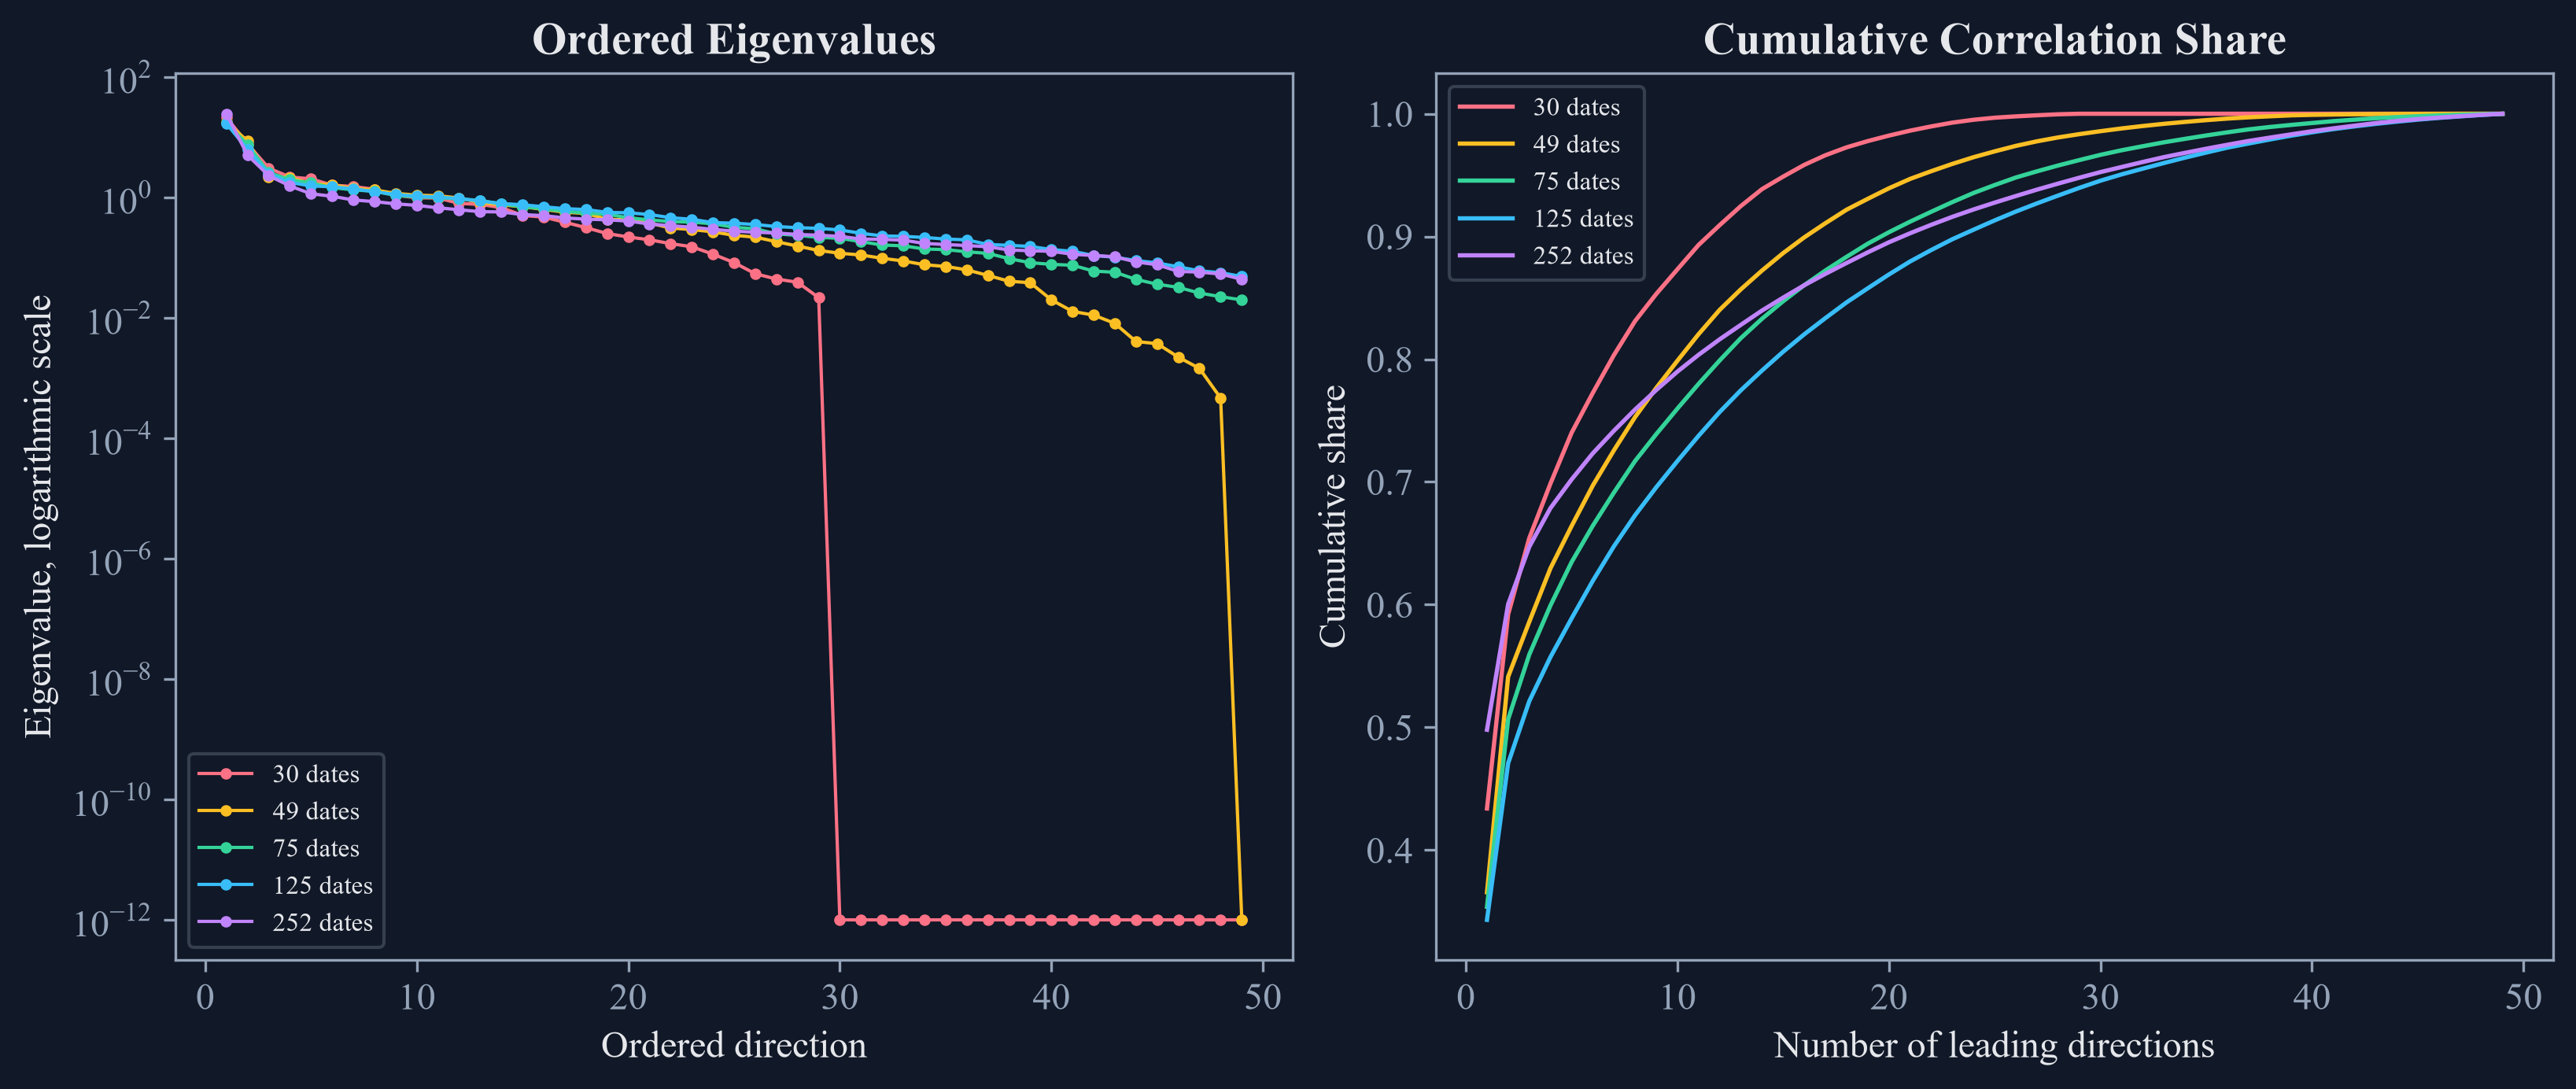

In [3]:
diagnostic_rows = []
spectra = {}
for observations in [30, 49, 75, 125, 252]:
    window = industry_returns.tail(observations)
    covariance = np.cov(window.to_numpy(), rowvar=False)
    current_correlation = cov_to_corr(covariance)
    eigenvalues = np.linalg.eigvalsh(current_correlation)
    eigenvalues = np.sort(eigenvalues)[::-1]
    spectra[observations] = eigenvalues
    tolerance = eigenvalues[0] * 1e-10
    positive = eigenvalues[eigenvalues > tolerance]
    weights = positive / positive.sum()
    rank = int(np.linalg.matrix_rank(current_correlation, tol=tolerance))
    condition_number = np.inf if rank < current_correlation.shape[0] else float(eigenvalues[0] / eigenvalues[-1])
    diagnostic_rows.append({"Observations": observations, "Portfolios": current_correlation.shape[0], "Observation to portfolio ratio": observations / current_correlation.shape[0], "Rank": rank, "Near-zero eigenvalues": int(np.sum(eigenvalues <= tolerance)), "Smallest eigenvalue": eigenvalues[-1], "Largest eigenvalue": eigenvalues[0], "Condition number": condition_number, "Effective rank": float(np.exp(-np.sum(weights * np.log(weights))))})
covariance_window_diagnostics = pd.DataFrame(diagnostic_rows)
eigenvalues_125 = spectra[125]
shares = eigenvalues_125 / eigenvalues_125.sum()
leading_eigenvalues = pd.DataFrame({"Ordered direction": np.arange(1, 11), "Eigenvalue": eigenvalues_125[:10], "Share of total correlation": shares[:10], "Cumulative share": np.cumsum(shares[:10])})
save_table(covariance_window_diagnostics, "covariance_window_diagnostics", "Rank and eigenvalue diagnostics as the public estimation window changes.", "tab:chapter9-window-diagnostics", fit=True)
save_table(leading_eigenvalues, "leading_eigenvalues", "Ten leading correlation eigenvalues in the 125-day public window.", "tab:chapter9-leading-eigenvalues", fit=True)
display(covariance_window_diagnostics.round(6))
display(leading_eigenvalues.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.5), constrained_layout=True)
colors = [palette["rose"], palette["amber"], palette["green"], palette["cyan"], palette["violet"]]
for observations, color in zip([30, 49, 75, 125, 252], colors):
    axes[0].plot(np.arange(1, 50), np.maximum(spectra[observations], 1e-12), marker="o", markersize=2.5, linewidth=1.0, color=color, label=f"{observations} dates")
    axes[1].plot(np.arange(1, 50), np.cumsum(np.maximum(spectra[observations], 0.0)) / np.maximum(spectra[observations], 0.0).sum(), linewidth=1.3, color=color, label=f"{observations} dates")
axes[0].set_yscale("log")
axes[0].set_title("Ordered Eigenvalues")
axes[0].set_xlabel("Ordered direction")
axes[0].set_ylabel("Eigenvalue, logarithmic scale")
axes[0].legend(fontsize=8)
axes[1].set_title("Cumulative Correlation Share")
axes[1].set_xlabel("Number of leading directions")
axes[1].set_ylabel("Cumulative share")
axes[1].legend(fontsize=8)
figure.savefig(FIGURES / "window_eigenvalue_spectra.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "window_eigenvalue_spectra.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "window_eigenvalue_spectra.png")))
plt.close(figure)

## Tests

In [4]:
assert industry_returns.shape == (1760, 49)
assert industry_returns.index.min() == pd.Timestamp('2019-01-02')
assert industry_returns.index.max() == pd.Timestamp('2025-12-31')
assert not industry_returns.isna().any().any()
assert np.allclose(np.diag(correlation), 1.0)
assert np.allclose(correlation, correlation.T)
assert covariance_window_diagnostics.loc[covariance_window_diagnostics['Observations'] == 30, 'Rank'].iloc[0] == 29
assert covariance_window_diagnostics.loc[covariance_window_diagnostics['Observations'] == 49, 'Rank'].iloc[0] == 48
assert covariance_window_diagnostics.loc[covariance_window_diagnostics['Observations'] == 75, 'Rank'].iloc[0] == 49
assert covariance_window_diagnostics['Near-zero eigenvalues'].tolist()[:2] == [20, 1]
assert covariance_window_diagnostics['Largest eigenvalue'].gt(1.0).all()
assert covariance_window_diagnostics['Effective rank'].between(1.0, 49.0).all()
assert np.isclose(spectra[125].sum(), 49.0)
assert np.all(np.diff(spectra[125]) <= 0.0)
assert np.all(np.diff(leading_eigenvalues['Cumulative share']) >= 0.0)
assert (FIGURES / 'industry_correlation.pdf').is_file()
assert (FIGURES / 'window_eigenvalue_spectra.pdf').is_file()
assert (TABLES / 'data_provenance.tex').is_file()
assert (TABLES / 'covariance_window_diagnostics.tex').is_file()
assert (TABLES / 'leading_eigenvalues.tex').is_file()
